# Smart Home Energy Consumption Analysis Using Bayesian Networks

In [1]:
pip install pgmpy pandas numpy matplotlib networkx

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\902pu\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


## Part A: Expert Bayesian Network

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from itertools import product
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination

STATES = {
    "W": ["Hot", "Mild", "Cold"],
    "D": ["Weekday", "Weekend"],
    "O": ["High", "Low"],
    "A": ["On", "Off"],
    "L": ["Heavy", "Light"],
    "E": ["High", "Low"]
}

EDGES = [
    ("W", "A"),
    ("D", "O"),
    ("O", "A"),
    ("O", "L"),
    ("A", "E"),
    ("L", "E")
]

model = DiscreteBayesianNetwork(EDGES)

cpd_w = TabularCPD(
    "W", 3,
    [[0.50], [0.30], [0.20]],
    state_names={"W": STATES["W"]}
)

cpd_d = TabularCPD(
    "D", 2,
    [[0.70], [0.30]],
    state_names={"D": STATES["D"]}
)

cpd_o = TabularCPD(
    "O", 2,
    [[0.45, 0.80],
     [0.55, 0.20]],
    evidence=["D"],
    evidence_card=[2],
    state_names={
        "O": STATES["O"],
        "D": STATES["D"]
    }
)

# Columns: Hot-High, Hot-Low, Mild-High,
# Mild-Low, Cold-High, Cold-Low

p_ac = [0.90, 0.60, 0.40, 0.15, 0.10, 0.05]

cpd_a = TabularCPD(
    "A", 2,
    [p_ac, [1-p for p in p_ac]],
    evidence=["W", "O"],
    evidence_card=[3, 2],
    state_names={
        "A": STATES["A"],
        "W": STATES["W"],
        "O": STATES["O"]
    }
)

cpd_l = TabularCPD(
    "L", 2,
    [[0.75, 0.35],
     [0.25, 0.65]],
    evidence=["O"],
    evidence_card=[2],
    state_names={
        "L": STATES["L"],
        "O": STATES["O"]
    }
)

# Columns: On-Heavy, On-Light, Off-Heavy, Off-Light

p_energy = [0.92, 0.68, 0.55, 0.12]

cpd_e = TabularCPD(
    "E", 2,
    [p_energy, [1-p for p in p_energy]],
    evidence=["A", "L"],
    evidence_card=[2, 2],
    state_names={
        "E": STATES["E"],
        "A": STATES["A"],
        "L": STATES["L"]
    }
)

model.add_cpds(
    cpd_w, cpd_d, cpd_o,
    cpd_a, cpd_l, cpd_e
)

print("Model valid:", model.check_model())

C:\Users\902pu\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\902pu\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\pgmpy\estimators\__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


Model valid: True


In [3]:
for cpd in model.get_cpds():

    sums = cpd.get_values().sum(axis=0)

    print(cpd.variable, sums)

    assert np.allclose(sums, 1.0)

print("All CPTs are valid.")

W [1.]
D [1.]
O [1. 1.]
A [1. 1. 1. 1. 1. 1.]
L [1. 1.]
E [1. 1. 1. 1.]
All CPTs are valid.


3. Visualize the Bayesian Network.

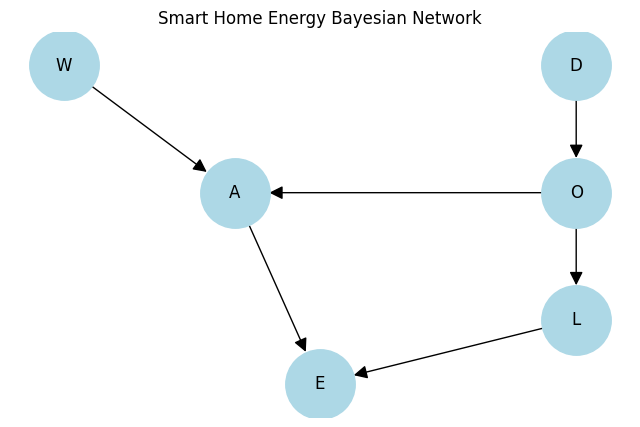

In [4]:
G = nx.DiGraph()
G.add_edges_from(EDGES)

pos = {
    "W": (0, 2),
    "D": (3, 2),
    "O": (3, 1),
    "A": (1, 1),
    "L": (3, 0),
    "E": (1.5, -0.5)
}

plt.figure(figsize=(8, 5))

nx.draw_networkx(
    G,
    pos,
    with_labels=True,
    node_size=2500,
    node_color="lightblue",
    edge_color="black",
    arrows=True,
    arrowsize=20,
    font_size=12
)

plt.title("Smart Home Energy Bayesian Network")
plt.axis("off")
plt.show()

4. Compute the following probabilities:

In [5]:
def posterior(model, variable, state, evidence=None):

    inference = VariableElimination(model)

    result = inference.query(
        variables=[variable],
        evidence=evidence or {},
        show_progress=False
    )

    return float(
        result.get_value(**{variable: state})
    )


def answer_queries(model):

    queries = {
        "Q1": posterior(model, "E", "High"),

        "Q2": posterior(
            model, "E", "High",
            {"W": "Hot"}
        ),

        "Q3": posterior(
            model, "E", "High",
            {"D": "Weekend"}
        ),

        "Q4": posterior(
            model, "E", "High",
            {"W": "Cold", "O": "High"}
        ),

        "Q5": posterior(
            model, "W", "Hot",
            {"E": "High"}
        ),

        "Q6": posterior(
            model, "A", "On",
            {"E": "High"}
        ),

        "Q7": posterior(
            model, "A", "On",
            {"E": "High", "L": "Heavy"}
        )
    }

    return pd.Series(queries)


expert_results = answer_queries(model)

print(expert_results.round(6))

Q1    0.580631
Q2    0.706266
Q3    0.640198
Q4    0.484250
Q5    0.608188
Q6    0.692867
Q7    0.649899
dtype: float64


5. Explaining Away (Q6 vs Q7)


Q6:
\[
P(A=On\mid E=High)=0.692867
\]

Q7:
\[
P(A=On\mid E=High,L=Heavy)=0.649899
\]

We observe that:
\[
Q7 < Q6
\]

The reason is that both AC usage and appliance load contribute to high energy consumption.

When we already know that appliance load is heavy, it provides one explanation for high energy consumption. Therefore, the probability that AC usage is also responsible decreases.

This phenomenon is called explaining away.

## Part B: Conditional Independence Analysis

In [6]:
print("B1: Weather independent of DayType")

print(
    posterior(model, "W", "Hot"),
    posterior(model, "W", "Hot",
              {"D": "Weekend"})
)

print("\nB2: Weather independent of DayType given E?")

print(
    posterior(model, "W", "Hot",
              {"E": "High"})
)

print(
    posterior(model, "W", "Hot",
              {"E": "High", "D": "Weekend"})
)

print("\nB3: Weather independent of Load given Occupancy")

print(
    posterior(model, "W", "Hot",
              {"O": "High"})
)

print(
    posterior(model, "W", "Hot",
              {"O": "High", "L": "Heavy"})
)

B1: Weather independent of DayType
0.5 0.5

B2: Weather independent of DayType given E?
0.6081880784748783
0.5997514833289987

B3: Weather independent of Load given Occupancy
0.5
0.5


## Part C: Synthetic Data Generation

In [7]:
SEED = 42
SIZES = [500, 5000, 20000]

def draw_state(rng, states, probabilities):
    return rng.choice(states, p=probabilities)


def sample_one(rng):

    # Weather
    w = draw_state(
        rng, STATES["W"],
        [0.50, 0.30, 0.20]
    )

    # Day Type
    d = draw_state(
        rng, STATES["D"],
        [0.70, 0.30]
    )

    # Occupancy
    p_occ = 0.45 if d == "Weekday" else 0.80

    o = draw_state(
        rng, STATES["O"],
        [p_occ, 1-p_occ]
    )

    # AC Usage
    p_ac = {
        ("Hot", "High"): 0.90,
        ("Hot", "Low"): 0.60,
        ("Mild", "High"): 0.40,
        ("Mild", "Low"): 0.15,
        ("Cold", "High"): 0.10,
        ("Cold", "Low"): 0.05
    }[(w, o)]

    a = draw_state(
        rng, STATES["A"],
        [p_ac, 1-p_ac]
    )

    # Appliance Load
    p_load = 0.75 if o == "High" else 0.35

    l = draw_state(
        rng, STATES["L"],
        [p_load, 1-p_load]
    )

    # Energy Consumption
    p_energy = {
        ("On", "Heavy"): 0.92,
        ("On", "Light"): 0.68,
        ("Off", "Heavy"): 0.55,
        ("Off", "Light"): 0.12
    }[(a, l)]

    e = draw_state(
        rng, STATES["E"],
        [p_energy, 1-p_energy]
    )

    return {
        "W": w,
        "D": d,
        "O": o,
        "A": a,
        "L": l,
        "E": e
    }


def generate_dataset(n, rng):

    return pd.DataFrame([
        sample_one(rng) for _ in range(n)
    ])


rng = np.random.default_rng(SEED)

datasets = {
    n: generate_dataset(n, rng)
    for n in SIZES
}

In [8]:
for n, data in datasets.items():

    print("\nDataset size:", n)

    print("\nWeather frequencies:")

    print(
        data["W"].value_counts()
        .reindex(STATES["W"], fill_value=0)
    )

    print("\nWeather relative frequencies:")

    print(
        data["W"].value_counts(normalize=True)
        .reindex(STATES["W"], fill_value=0)
        .round(4)
    )

    print("\nWeather and Occupancy combinations:")

    print(
        pd.crosstab(data["W"], data["O"])
        .reindex(
            index=STATES["W"],
            columns=STATES["O"],
            fill_value=0
        )
    )


Dataset size: 500

Weather frequencies:
W
Hot     255
Mild    143
Cold    102
Name: count, dtype: int64

Weather relative frequencies:
W
Hot     0.510
Mild    0.286
Cold    0.204
Name: proportion, dtype: float64

Weather and Occupancy combinations:
O     High  Low
W              
Hot    155  100
Mild    75   68
Cold    51   51

Dataset size: 5000

Weather frequencies:
W
Hot     2487
Mild    1526
Cold     987
Name: count, dtype: int64

Weather relative frequencies:
W
Hot     0.4974
Mild    0.3052
Cold    0.1974
Name: proportion, dtype: float64

Weather and Occupancy combinations:
O     High   Low
W               
Hot   1393  1094
Mild   841   685
Cold   570   417

Dataset size: 20000

Weather frequencies:
W
Hot     9980
Mild    6074
Cold    3946
Name: count, dtype: int64

Weather relative frequencies:
W
Hot     0.4990
Mild    0.3037
Cold    0.1973
Name: proportion, dtype: float64

Weather and Occupancy combinations:
O     High   Low
W               
Hot   5530  4450
Mild  3427  2647
Co

## Part D: Learning from Data

1. Learn the network parameters using both:

In [9]:
def learn_model(data, estimator_name):

    ESS = 10

    parents = {
        "W": [],
        "D": [],
        "O": ["D"],
        "A": ["W", "O"],
        "L": ["O"],
        "E": ["A", "L"]
    }

    learned_cpds = []

    for var, par in parents.items():

        child_states = STATES[var]
        r = len(child_states)

        if par:
            configurations = list(
                product(*(STATES[p] for p in par))
            )
        else:
            configurations = [()]

        q = len(configurations)
        values = []

        for cfg in configurations:

            subset = data

            for p, value in zip(par, cfg):
                subset = subset[subset[p] == value]

            N = len(subset)
            row = []

            for state in child_states:

                count = (subset[var] == state).sum()

                if estimator_name == "MLE":

                    if N == 0:
                        probability = 1 / r
                    else:
                        probability = count / N

                elif estimator_name == "Bayesian":

                    alpha = ESS / (q * r)
                    alpha_total = ESS / q

                    probability = (
                        count + alpha
                    ) / (
                        N + alpha_total
                    )

                else:
                    raise ValueError("Unknown estimator")

                row.append(probability)

            values.append(row)

        # TabularCPD expects child states as rows
        values = np.array(values).T.tolist()

        state_names = {var: child_states}

        for p in par:
            state_names[p] = STATES[p]

        kwargs = {}

        if par:
            kwargs["evidence"] = par
            kwargs["evidence_card"] = [
                len(STATES[p]) for p in par
            ]

        cpd = TabularCPD(
            variable=var,
            variable_card=r,
            values=values,
            state_names=state_names,
            **kwargs
        )

        learned_cpds.append(cpd)

    learned_model = DiscreteBayesianNetwork(EDGES)

    learned_model.add_nodes_from(STATES.keys())
    learned_model.add_cpds(*learned_cpds)

    assert learned_model.check_model()

    return learned_model

In [10]:
learned_models = {}

for n, data in datasets.items():

    learned_models[(n, "MLE")] = learn_model(
        data, "MLE"
    )

    learned_models[(n, "Bayesian")] = learn_model(
        data, "Bayesian"
    )

print("All six models learned successfully.")

All six models learned successfully.


In [11]:
print("Expert AC CPT")
print(model.get_cpds("A"))

for n in SIZES:

    print("\nMLE AC CPT:", n)
    print(learned_models[(n, "MLE")].get_cpds("A"))

    print("\nBayesian AC CPT:", n)
    print(learned_models[(n, "Bayesian")].get_cpds("A"))

Expert AC CPT
+--------+---------------------+-----+---------+---------+---------+
| W      | W(Hot)              | ... | W(Mild) | W(Cold) | W(Cold) |
+--------+---------------------+-----+---------+---------+---------+
| O      | O(High)             | ... | O(Low)  | O(High) | O(Low)  |
+--------+---------------------+-----+---------+---------+---------+
| A(On)  | 0.9                 | ... | 0.15    | 0.1     | 0.05    |
+--------+---------------------+-----+---------+---------+---------+
| A(Off) | 0.09999999999999998 | ... | 0.85    | 0.9     | 0.95    |
+--------+---------------------+-----+---------+---------+---------+

MLE AC CPT: 500
+--------+---------------------+-----+--------------------+
| W      | W(Hot)              | ... | W(Cold)            |
+--------+---------------------+-----+--------------------+
| O      | O(High)             | ... | O(Low)             |
+--------+---------------------+-----+--------------------+
| A(On)  | 0.8516129032258064  | ... | 0.0196078

In [12]:
# Perform Q1-Q7 on all learned models

learned_results = {}

for n in SIZES:

    for estimator in ["MLE", "Bayesian"]:

        learned_model = learned_models[(n, estimator)]

        results = answer_queries(learned_model)

        learned_results[(n, estimator)] = results

        print("\nDataset Size:", n)
        print("Estimator:", estimator)

        print(results.round(6))


Dataset Size: 500
Estimator: MLE
Q1    0.556977
Q2    0.704969
Q3    0.609242
Q4    0.420305
Q5    0.645510
Q6    0.727981
Q7    0.658365
dtype: float64

Dataset Size: 500
Estimator: Bayesian
Q1    0.555939
Q2    0.699108
Q3    0.604562
Q4    0.426789
Q5    0.636983
Q6    0.723610
Q7    0.655952
dtype: float64

Dataset Size: 5000
Estimator: MLE
Q1    0.581455
Q2    0.703291
Q3    0.642807
Q4    0.489374
Q5    0.601624
Q6    0.686990
Q7    0.651279
dtype: float64

Dataset Size: 5000
Estimator: Bayesian
Q1    0.581298
Q2    0.702733
Q3    0.642187
Q4    0.489704
Q5    0.600912
Q6    0.686632
Q7    0.651023
dtype: float64

Dataset Size: 20000
Estimator: MLE
Q1    0.577866
Q2    0.703316
Q3    0.639442
Q4    0.485401
Q5    0.607329
Q6    0.695483
Q7    0.652302
dtype: float64

Dataset Size: 20000
Estimator: Bayesian
Q1    0.577828
Q2    0.703176
Q3    0.639289
Q4    0.485490
Q5    0.607146
Q6    0.695390
Q7    0.652237
dtype: float64


In [13]:
results_table = pd.DataFrame({
    "Expert": expert_results
})

for n in SIZES:

    for estimator in ["MLE", "Bayesian"]:

        results_table[f"{estimator}_{n}"] = (
            learned_results[(n, estimator)]
        )

print(results_table.round(6))

      Expert   MLE_500  Bayesian_500  MLE_5000  Bayesian_5000  MLE_20000  \
Q1  0.580631  0.556977      0.555939  0.581455       0.581298   0.577866   
Q2  0.706266  0.704969      0.699108  0.703291       0.702733   0.703316   
Q3  0.640198  0.609242      0.604562  0.642807       0.642187   0.639442   
Q4  0.484250  0.420305      0.426789  0.489374       0.489704   0.485401   
Q5  0.608188  0.645510      0.636983  0.601624       0.600912   0.607329   
Q6  0.692867  0.727981      0.723610  0.686990       0.686632   0.695483   
Q7  0.649899  0.658365      0.655952  0.651279       0.651023   0.652302   

    Bayesian_20000  
Q1        0.577828  
Q2        0.703176  
Q3        0.639289  
Q4        0.485490  
Q5        0.607146  
Q6        0.695390  
Q7        0.652237  


## Part E: Comparative Analysis

In [20]:
# Expert model results
expert_results = answer_queries(model)

# Store comparison tables
comparison_tables = {}

for n in SIZES:
    table = pd.DataFrame({
        "Expert Model": expert_results,
        "MLE Model": learned_results[(n, "MLE")],
        "Bayesian Model": learned_results[(n, "Bayesian")]
    })

    table["|Diff| MLE"] = (
        table["MLE Model"] - table["Expert Model"]
    ).abs()

    table["|Diff| Bayesian"] = (
        table["Bayesian Model"] - table["Expert Model"]
    ).abs()

    comparison_tables[n] = table

    print(f"\nDataset Size: {n}")
    print(table.round(6))


Dataset Size: 500
    Expert Model  MLE Model  Bayesian Model  |Diff| MLE  |Diff| Bayesian
Q1      0.580631   0.556977        0.555939    0.023654         0.024692
Q2      0.706266   0.704969        0.699108    0.001297         0.007158
Q3      0.640198   0.609242        0.604562    0.030956         0.035636
Q4      0.484250   0.420305        0.426789    0.063945         0.057461
Q5      0.608188   0.645510        0.636983    0.037322         0.028795
Q6      0.692867   0.727981        0.723610    0.035114         0.030743
Q7      0.649899   0.658365        0.655952    0.008466         0.006052

Dataset Size: 5000
    Expert Model  MLE Model  Bayesian Model  |Diff| MLE  |Diff| Bayesian
Q1      0.580631   0.581455        0.581298    0.000824         0.000667
Q2      0.706266   0.703291        0.702733    0.002974         0.003533
Q3      0.640198   0.642807        0.642187    0.002609         0.001989
Q4      0.484250   0.489374        0.489704    0.005124         0.005454
Q5      0.60

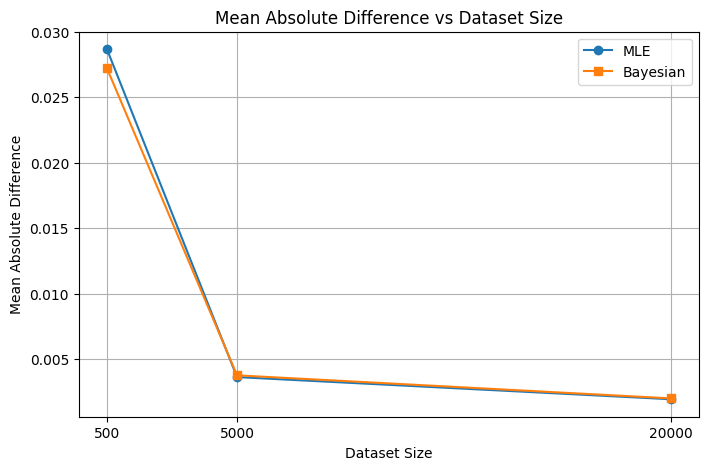

In [21]:
mean_errors = {
    "MLE": [],
    "Bayesian": []
}

for n in SIZES:
    table = comparison_tables[n]

    mean_errors["MLE"].append(table["|Diff| MLE"].mean())
    mean_errors["Bayesian"].append(table["|Diff| Bayesian"].mean())

plt.figure(figsize=(8, 5))

plt.plot(SIZES, mean_errors["MLE"], marker="o", label="MLE")
plt.plot(SIZES, mean_errors["Bayesian"], marker="s", label="Bayesian")

plt.xlabel("Dataset Size")
plt.ylabel("Mean Absolute Difference")
plt.title("Mean Absolute Difference vs Dataset Size")
plt.xticks(SIZES)
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
table_500 = comparison_tables[500]

print("MLE largest error:")
print(table_500["|Diff| MLE"].idxmax())
print(table_500["|Diff| MLE"].max())

print("\nBayesian largest error:")
print(table_500["|Diff| Bayesian"].idxmax())
print(table_500["|Diff| Bayesian"].max())

MLE largest error:
Q4
0.06394461735074752

Bayesian largest error:
Q4
0.05746050100435807


3.Which estimator performs better for small datasets?
For the 500-sample dataset, Bayesian Estimation performs slightly better than MLE. Its mean absolute error is 0.027220 compared with 0.028679 for MLE.

This happens because Bayesian estimation uses a prior distribution that smooths the probability estimates. It reduces the effect of small sample counts and prevents extreme estimates. However, for larger datasets, MLE performs slightly better in this experiment. As the number of samples increases, the influence of the prior becomes smaller, and both estimators produce results close to the expert model.